In [ ]:
import itertools as it

from IPython.display import display
import marimo as mo
import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns
from teeplot import teeplot as tp
from watermark import watermark

from pylib._osf_fetch import osf_fetch
from pylib.theory._calc_mutator_fixprob_closed import (
    calc_mutator_fixprob_closed,
)
from pylib.viz._get_nben_cmap import get_nben_cmap
from pylib.viz._get_nben_hue_norm import get_nben_hue_norm
from pylib.viz._size_fixation_areaplot import size_fixation_areaplot
from pylib.viz._size_fixation_cliffplot import size_fixation_cliffplot
from pylib.viz._size_fixation_heatmap import size_fixation_heatmap

In [ ]:
mo.md(
    f"""
```Text
{watermark(
    current_date=True,
    iso8601=True,
    machine=True,
    updated=True,
    python=True,
    iversions=True,
    globals_=globals(),
)}
```
"""
)

```Text
Last updated: 2026-11-26T01:14:53.933028+00:00

Python implementation: CPython
Python version       : 3.10.22
IPython version      : 7.31.1

Compiler    : GCC 13.3.0
OS          : Linux
Release     : 7.0.0-1017-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 4
Architecture: 64bit

seaborn: 0.13.2
numpy  : 2.1.2
pandas : 2.2.3
polars : 1.9.0
teeplot: 1.2.0
marimo : 0.23.2

```

In [ ]:
teeplot_subdir = "wse-5050-spatial2d-2048atile-traits"
teeplot_subdir

'wse-5050-spatial2d-2048atile-traits'

## Prep Data

In [ ]:
dfxs = pd.concat(
    [
        pd.read_parquet(osf_fetch("https://osf.io/b7xzc/download")),
        pd.read_parquet(osf_fetch("https://osf.io/mz7wt/download")),
        pd.read_parquet(osf_fetch("https://osf.io/7r8hx/download")),
        pd.read_parquet(osf_fetch("https://osf.io/369g8/download")),
        pd.read_parquet(osf_fetch("https://osf.io/d29z6/download")),
        pd.read_parquet(osf_fetch("https://osf.io/s6mwg/download")),
    ],
)
display(dfxs.describe()), display(dfxs.head()), display(dfxs.tail())

downloading https://osf.io/b7xzc/download -> /tmp/b7xzc
size: 6720354 bytes
downloading https://osf.io/mz7wt/download -> /tmp/mz7wt
size: 6750264 bytes
downloading https://osf.io/7r8hx/download -> /tmp/7r8hx
size: 6738379 bytes
downloading https://osf.io/369g8/download -> /tmp/369g8
size: 6721597 bytes
downloading https://osf.io/d29z6/download -> /tmp/d29z6
size: 6721321 bytes
downloading https://osf.io/s6mwg/download -> /tmp/s6mwg
size: 6722307 bytes


In [ ]:
apn = dfxs["population size"].min()  # agents per node
apn

np.uint64(2048)

In [ ]:
dfxs["genotype"] = dfxs["genotype"].map(
    {
        "normomutator": "nonmutator",
        "hypermutator": "mutator",
    },
)

## Size Fixation Curves

In [ ]:
for _errorbar in "sd", "se", "ci", None:
    tp.tee(
        sns.relplot,
        data=dfxs,
        x="population size",
        y="fixation probability",
        hue="genotype",
        hue_order=["nonmutator", "mutator"],
        col="available beneficial mutations",
        style="genotype",
        style_order=["nonmutator", "mutator"],
        aspect=1.5,
        col_wrap=3,
        errorbar=_errorbar,
        height=2,
        kind="line",
        markers=True,
        seed=1,
        teeplot_outexclude="post",
        teeplot_subdir=teeplot_subdir,
        teeplot_postprocess=f"""
teed.set(xscale="log", ylim=(-0.02, 1.02))
teed.figure.suptitle("n={apn} agents per node", x=0.63, y=1.02)
teed.set_titles(col_template="{{col_var}} = {{col_name:.0f}}")
sns.move_legend(
    teed,
    "lower center",
    bbox_to_anchor=(0.25, 0.97),
    frameon=False,
    ncol=2,
    title=None,
)
""",
    )

teeplots/wse-5050-spatial2d-2048atile-traits/col=available-beneficial-mutations+errorbar=sd+hue=genotype+kind=line+style=genotype+viz=relplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-2048atile-traits/col=available-beneficial-mutations+errorbar=sd+hue=genotype+kind=line+style=genotype+viz=relplot+x=population-size+y=fixation-probability+ext=.png
teeplots/wse-5050-spatial2d-2048atile-traits/col=available-beneficial-mutations+errorbar=se+hue=genotype+kind=line+style=genotype+viz=relplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-2048atile-traits/col=available-beneficial-mutations+errorbar=se+hue=genotype+kind=line+style=genotype+viz=relplot+x=population-size+y=fixation-probability+ext=.png
teeplots/wse-5050-spatial2d-2048atile-traits/col=available-beneficial-mutations+errorbar=ci+hue=genotype+kind=line+style=genotype+viz=relplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-2048atile-tr

In [ ]:
for _errorbar in "sd", "se", "ci", None:
    tp.tee(
        sns.relplot,
        data=dfxs[dfxs["genotype"] == "mutator"],
        x="population size",
        y="fixation probability",
        hue="available beneficial mutations",
        aspect=1.5,
        height=3,
        kind="line",
        errorbar=_errorbar,
        linewidth=2,
        markers=True,
        palette=get_nben_cmap(),
        hue_norm=get_nben_hue_norm(),
        seed=1,
        teeplot_outexclude="post",
        teeplot_postprocess=f"""
teed.set(xscale="log", ylim=(-0.02, 1.02))
teed.figure.suptitle("n={apn} agents per node", x=0.63, y=1.02)
teed.set_titles(col_template='{{col_var}} = {{col_name:.0f}}')
""",
        teeplot_subdir=teeplot_subdir,
    )

teeplots/wse-5050-spatial2d-2048atile-traits/errorbar=sd+hue=available-beneficial-mutations+kind=line+viz=relplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-2048atile-traits/errorbar=sd+hue=available-beneficial-mutations+kind=line+viz=relplot+x=population-size+y=fixation-probability+ext=.png
teeplots/wse-5050-spatial2d-2048atile-traits/errorbar=se+hue=available-beneficial-mutations+kind=line+viz=relplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-2048atile-traits/errorbar=se+hue=available-beneficial-mutations+kind=line+viz=relplot+x=population-size+y=fixation-probability+ext=.png
teeplots/wse-5050-spatial2d-2048atile-traits/errorbar=ci+hue=available-beneficial-mutations+kind=line+viz=relplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-2048atile-traits/errorbar=ci+hue=available-beneficial-mutations+kind=line+viz=relplot+x=population-size+y=fixation-probability+ext=.png
teeplots/wse-505

## Size Fixation Cliffplot

In [ ]:
dfxs["available\nbeneficial mutations"] = dfxs[
    "available beneficial mutations"
]

In [ ]:
for col_label, _errorbar, layout in it.product(
    ["", None],
    ["ci", None],
    ["skinny", "wide"],
):
    tp.tee(
        size_fixation_cliffplot,
        fixprobs_df=dfxs[
            # exclude non-9-scaled wafer-filling data
            np.isclose(
                np.mod(
                    np.log(dfxs["population size"] // apn) / np.log(9), 1.0
                ),
                0.0,
            )
        ].reset_index(drop=True),
        x="fixation probability",
        y="available\nbeneficial mutations",
        col="population size",
        hue="genotype",
        hue_order=["nonmutator", "mutator"],
        col_label=col_label,
        errorbar=_errorbar,
        layout=layout,
        ylim=(1, 4),
        teeplot_subdir=teeplot_subdir,
    )

/home/runner/work/hypermutator-dynamics/hypermutator-dynamics/bindle/pylib/viz/_size_fixation_cliffplot.py:29: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  g = sns.relplot(


teeplots/wse-5050-spatial2d-2048atile-traits/col=population-size+col-label=+errorbar=ci+hue=genotype+layout=skinny+viz=size-fixation-cliffplot+x=fixation-probability+y=available-beneficial-mutations+ext=.pdf
teeplots/wse-5050-spatial2d-2048atile-traits/col=population-size+col-label=+errorbar=ci+hue=genotype+layout=skinny+viz=size-fixation-cliffplot+x=fixation-probability+y=available-beneficial-mutations+ext=.png


/home/runner/work/hypermutator-dynamics/hypermutator-dynamics/bindle/pylib/viz/_size_fixation_cliffplot.py:29: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  g = sns.relplot(


teeplots/wse-5050-spatial2d-2048atile-traits/col=population-size+col-label=+errorbar=ci+hue=genotype+layout=wide+viz=size-fixation-cliffplot+x=fixation-probability+y=available-beneficial-mutations+ext=.pdf
teeplots/wse-5050-spatial2d-2048atile-traits/col=population-size+col-label=+errorbar=ci+hue=genotype+layout=wide+viz=size-fixation-cliffplot+x=fixation-probability+y=available-beneficial-mutations+ext=.png


/home/runner/work/hypermutator-dynamics/hypermutator-dynamics/bindle/pylib/viz/_size_fixation_cliffplot.py:29: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  g = sns.relplot(


teeplots/wse-5050-spatial2d-2048atile-traits/col=population-size+col-label=+hue=genotype+layout=skinny+viz=size-fixation-cliffplot+x=fixation-probability+y=available-beneficial-mutations+ext=.pdf
teeplots/wse-5050-spatial2d-2048atile-traits/col=population-size+col-label=+hue=genotype+layout=skinny+viz=size-fixation-cliffplot+x=fixation-probability+y=available-beneficial-mutations+ext=.png


... (6 outputs left out)

/home/runner/work/hypermutator-dynamics/hypermutator-dynamics/bindle/pylib/viz/_size_fixation_cliffplot.py:29: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  g = sns.relplot(


teeplots/wse-5050-spatial2d-2048atile-traits/col=population-size+hue=genotype+layout=skinny+viz=size-fixation-cliffplot+x=fixation-probability+y=available-beneficial-mutations+ext=.pdf
teeplots/wse-5050-spatial2d-2048atile-traits/col=population-size+hue=genotype+layout=skinny+viz=size-fixation-cliffplot+x=fixation-probability+y=available-beneficial-mutations+ext=.png


/home/runner/work/hypermutator-dynamics/hypermutator-dynamics/bindle/pylib/viz/_size_fixation_cliffplot.py:29: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  g = sns.relplot(


teeplots/wse-5050-spatial2d-2048atile-traits/col=population-size+hue=genotype+layout=wide+viz=size-fixation-cliffplot+x=fixation-probability+y=available-beneficial-mutations+ext=.pdf
teeplots/wse-5050-spatial2d-2048atile-traits/col=population-size+hue=genotype+layout=wide+viz=size-fixation-cliffplot+x=fixation-probability+y=available-beneficial-mutations+ext=.png


In [ ]:
# math model predictions (see pylib/theory), for a 2D lattice of demes;
# the smallest population surveyed is a single deme
deme_size = int(dfxs["population size"].min())
model_N = np.geomspace(
    dfxs["population size"].min(), dfxs["population size"].max(), 60
)
model_xy = {
    float(K): (
        model_N.tolist(),
        [
            calc_mutator_fixprob_closed(N, K, deme_size=deme_size)
            for N in model_N
        ],
    )
    for K in sorted(dfxs["available beneficial mutations"].unique())
    if K <= 5
}

/home/runner/work/hypermutator-dynamics/hypermutator-dynamics/bindle/pylib/theory/_calc_drift_fixprob.py:15: RuntimeWarning: overflow encountered in expm1
  return float(np.expm1(a * x0) / np.expm1(a))


## Size Fixation Areaplot

In [ ]:
for _errorbar in "sd", "se", "ci", None:
    tp.tee(
        size_fixation_areaplot,
        fixprobs_df=dfxs[dfxs["available beneficial mutations"] <= 5],
        x="population size",
        y="fixation probability",
        hue="genotype",
        hue_order=["nonmutator", "mutator"],
        col="available\nbeneficial mutations",
        style="genotype",
        style_order=["nonmutator", "mutator"],
        col_wrap=3,
        errorbar=_errorbar,
        facet_kws=dict(legend_out=False),
        height=2,
        markers=True,
        teeplot_outexclude="post",
        teeplot_subdir=teeplot_subdir,
        teeplot_postprocess="""
teed.set_titles(col_template="{col_var} = {col_name:.0f}")
sns.move_legend(teed, "upper left", bbox_to_anchor=(.7, .4), frameon=False)
"""
        + f"""for (__, ax), xy in zip(
    sorted(teed.axes_dict.items()),
    {[model_xy[K] for K in sorted(model_xy)]!r},
):
    ax.plot(*xy, color="black", linestyle="--")
"""
        + "from pylib.viz._add_legend_entry import add_legend_entry\n"
        + 'add_legend_entry(teed, "analytic\\napprox")\n',
    )

/home/runner/work/hypermutator-dynamics/hypermutator-dynamics/bindle/pylib/viz/_size_fixation_areaplot.py:24: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  g = sns.relplot(


teeplots/wse-5050-spatial2d-2048atile-traits/col=available-beneficial-mutations+errorbar=sd+hue=genotype+style=genotype+viz=size-fixation-areaplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-2048atile-traits/col=available-beneficial-mutations+errorbar=sd+hue=genotype+style=genotype+viz=size-fixation-areaplot+x=population-size+y=fixation-probability+ext=.png


/home/runner/work/hypermutator-dynamics/hypermutator-dynamics/bindle/pylib/viz/_size_fixation_areaplot.py:24: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  g = sns.relplot(


teeplots/wse-5050-spatial2d-2048atile-traits/col=available-beneficial-mutations+errorbar=se+hue=genotype+style=genotype+viz=size-fixation-areaplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-2048atile-traits/col=available-beneficial-mutations+errorbar=se+hue=genotype+style=genotype+viz=size-fixation-areaplot+x=population-size+y=fixation-probability+ext=.png


/home/runner/work/hypermutator-dynamics/hypermutator-dynamics/bindle/pylib/viz/_size_fixation_areaplot.py:24: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  g = sns.relplot(


teeplots/wse-5050-spatial2d-2048atile-traits/col=available-beneficial-mutations+errorbar=ci+hue=genotype+style=genotype+viz=size-fixation-areaplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-2048atile-traits/col=available-beneficial-mutations+errorbar=ci+hue=genotype+style=genotype+viz=size-fixation-areaplot+x=population-size+y=fixation-probability+ext=.png


/home/runner/work/hypermutator-dynamics/hypermutator-dynamics/bindle/pylib/viz/_size_fixation_areaplot.py:24: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  g = sns.relplot(


teeplots/wse-5050-spatial2d-2048atile-traits/col=available-beneficial-mutations+hue=genotype+style=genotype+viz=size-fixation-areaplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-2048atile-traits/col=available-beneficial-mutations+hue=genotype+style=genotype+viz=size-fixation-areaplot+x=population-size+y=fixation-probability+ext=.png


## Size Fixation Heatmap

teeplots/wse-5050-spatial2d-2048atile-traits/genotype=mutator+index=available-beneficial-mutations+on=population-size+values=fixation-probability+viz=size-fixation-heatmap+ext=.pdf
teeplots/wse-5050-spatial2d-2048atile-traits/genotype=mutator+index=available-beneficial-mutations+on=population-size+values=fixation-probability+viz=size-fixation-heatmap+ext=.png


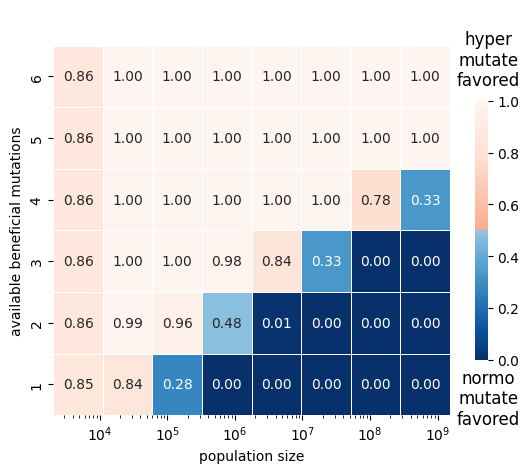

In [ ]:
tp.tee(
    size_fixation_heatmap,
    fixprobs_df=dfxs,
    genotype="mutator",
    index="available beneficial mutations",
    on="population size",
    values="fixation probability",
    teeplot_subdir=teeplot_subdir,
)

## Quality Check: Number Replicates Available

In [ ]:
categories = (
    pl.DataFrame(dfxs)
    .group_by(
        "population size",
    )
    .first()["population size"]
    .sort()
    .cast(pl.String)
    .to_list()
)
categories

In [ ]:
dfy = pl.DataFrame(dfxs).with_columns(
    pl.col("population size")
    .cast(pl.String)
    .cast(pl.Enum(categories))
    .alias("population size cat"),
)
display(dfy.describe()), display(dfy.head()), display(dfy.tail())

teeplots/wse-5050-spatial2d-2048atile-traits/col=available-beneficial-mutations+hue=genotype+kind=hist+multiple=dodge+viz=displot+x=population-size-cat+ext=.pdf
teeplots/wse-5050-spatial2d-2048atile-traits/col=available-beneficial-mutations+hue=genotype+kind=hist+multiple=dodge+viz=displot+x=population-size-cat+ext=.png


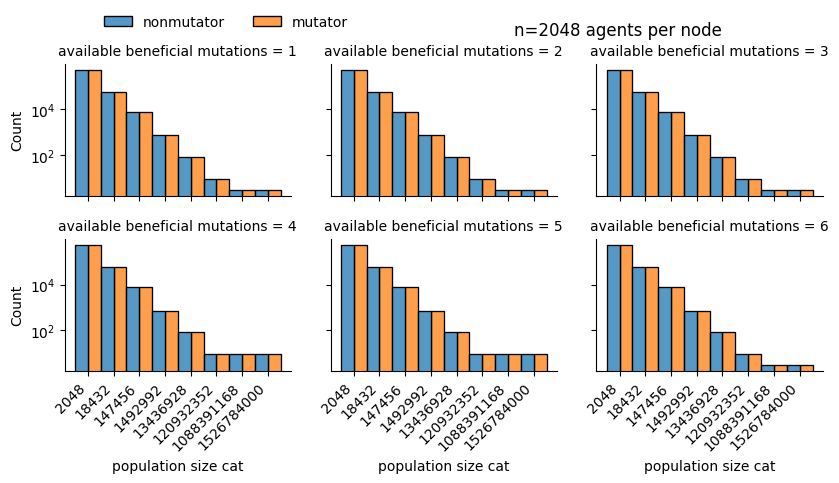

In [ ]:
tp.tee(
    sns.displot,
    data=dfy.to_pandas(),
    x="population size cat",
    hue="genotype",
    hue_order=["nonmutator", "mutator"],
    col="available beneficial mutations",
    aspect=1.5,
    col_wrap=3,
    height=2,
    kind="hist",
    multiple="dodge",
    teeplot_outexclude="post",
    teeplot_postprocess=f"""
teed.set(yscale='log')
teed.figure.suptitle("n={apn} agents per node", x=0.63, y=1.02)
teed.set_titles(col_template='{{col_var}} = {{col_name:.0f}}')
for ax in teed.axes.flat:
    for label in ax.get_xticklabels():
        label.set_rotation(45)
        label.set_ha("right")
sns.move_legend(
    teed, "lower center",
    bbox_to_anchor=(0.25, 0.97),
    frameon=False,
    ncol=2,
    title=None,
)
""",
    teeplot_subdir=teeplot_subdir,
)

## Quality Check: Has Reached Fixation?

In [ ]:
dfxs_ = dfxs[dfxs["genotype"] == "mutator"].copy().reset_index(drop=True)

In [ ]:
dfxs_["neither fixed"] = (dfxs_["fixation probability"] != 1.0) & (
    dfxs_["fixation probability"] != 0.0
)
any_unfixed = dfxs_["neither fixed"].any()
any_unfixed

np.True_

teeplots/wse-5050-spatial2d-2048atile-traits/col=available-beneficial-mutations+hue=genotype+kind=scatter+style=genotype+viz=relplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-2048atile-traits/col=available-beneficial-mutations+hue=genotype+kind=scatter+style=genotype+viz=relplot+x=population-size+y=fixation-probability+ext=.png


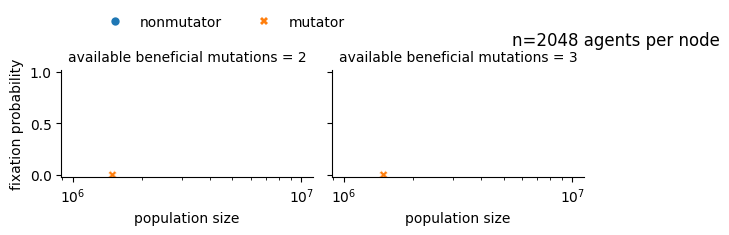

In [ ]:
tp.tee(
    sns.relplot,
    data=dfxs_[dfxs_["neither fixed"]],
    x="population size",
    y="fixation probability",
    hue="genotype",
    hue_order=["nonmutator", "mutator"],
    col=[None, "available beneficial mutations"][int(any_unfixed)],
    style="genotype",
    style_order=["nonmutator", "mutator"],
    aspect=1.5,
    col_wrap=[None, 3][int(any_unfixed)],
    height=2,
    kind="scatter",
    markers=bool(any_unfixed),
    teeplot_outexclude="post",
    teeplot_postprocess=f"""
teed.set(xscale='log', ylim=(-0.02, 1.02))
teed.figure.suptitle("n={apn} agents per node", x=0.63, y=1.02)
teed.set_titles(col_template='{{col_var}} = {{col_name:.0f}}')
try:
    sns.move_legend(
        teed,
        "lower center",
        bbox_to_anchor=(0.25, 0.97),
        frameon=False,
        ncol=2,
        title=None,
    )
except ValueError:
    pass
""",
    teeplot_subdir=teeplot_subdir,
)

teeplots/wse-5050-spatial2d-2048atile-traits/col=available-beneficial-mutations+hue=neither-fixed+multiple=fill+palette=pastel2+viz=displot+x=population-size+ext=.pdf
teeplots/wse-5050-spatial2d-2048atile-traits/col=available-beneficial-mutations+hue=neither-fixed+multiple=fill+palette=pastel2+viz=displot+x=population-size+ext=.png


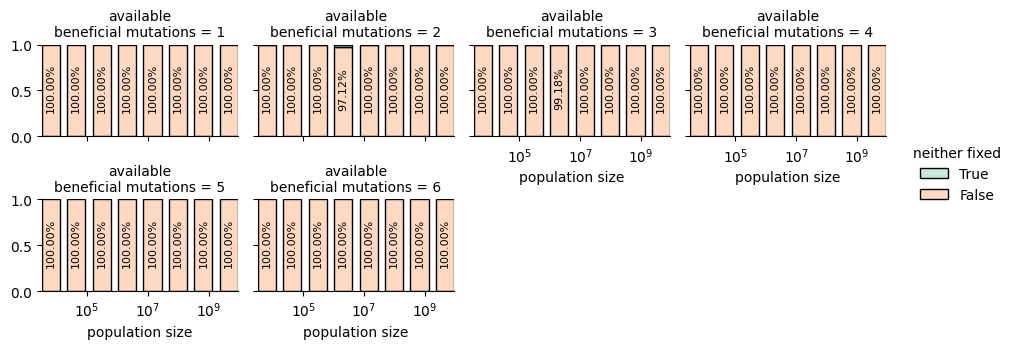

In [ ]:
saveit, teed = tp.tee(
    sns.displot,
    data=dfxs_.replace(
        # top surveyed value is of 9x growth pattern,
        # so nudge it to prevent binning issues
        dfxs_["population size"].max(),
        sorted(dfxs_["population size"].unique())[-2] * 9,
    ).reset_index(drop=True),
    x="population size",
    hue="neither fixed",
    hue_order=[True, False],
    col="available\nbeneficial mutations",
    col_wrap=4,
    aspect=1.3,
    height=1.8,
    multiple="fill",
    bins=dfxs_["population size"].nunique(),
    log_scale=(True, False),
    shrink=0.8,
    palette="Pastel2",
    teeplot_callback=True,
    teeplot_subdir=teeplot_subdir,
)

teed.set_titles(col_template="{col_var} = {col_name:.0f}")
teed.set_ylabels("")
# adapted from https://stackoverflow.com/a/68850867
for ax in teed.axes.ravel():
    # add annotations
    for c in ax.containers:
        # custom label calculates percent and add an empty string so 0 value bars don't have a number
        labels = [
            f"{w * 100:0.2f}%" if (w := v.get_height()) > 0.5 else ""
            for v in c
        ]
        ax.bar_label(
            c,
            labels=labels,
            label_type="center",
            fontsize=8,
            rotation=90,
            padding=2,
        )

saveit()